## 6. Аналіз шляху користувача та воронок конверсії (User Journey & Funnel Analysis)

In [1]:
# Імпортуємо необхідні бібліотеки

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
# Знаходимо папку з очищеними даними

current_dir = Path.cwd()

possible_paths = [
    parent / "data_processed"
    for parent in [current_dir, *current_dir.parents]
]

processed_path = next(
    (path for path in possible_paths if path.is_dir()),
    None
)

if processed_path is None:
    raise FileNotFoundError(
        "Не вдалося знайти папку data_processed"
    )

# Завантажуємо очищені датасети

csv_files = sorted(processed_path.glob("*.csv"))

if len(csv_files) != 13:
    raise ValueError(
        f"Очікувалося 13 датасетів, знайдено {len(csv_files)}"
    )

datasets = {
    file.stem: pd.read_csv(file)
    for file in csv_files
}

# Відновлюємо типи ідентифікаторів та часових міток

id_columns = [
    "user_id",
    "participant_id",
    "room_id",
    "archive_session_id",
    "title_id",
    "room_title_id"
]

timestamp_columns = [
    "event_timestamp",
    "started_at",
    "completed_at"
]

for df in datasets.values():

    for column in id_columns:

        if column in df.columns:

            df[column] = pd.to_numeric(
                df[column],
                errors="coerce"
            ).astype("Int64")

    for column in timestamp_columns:

        if column in df.columns:

            df[column] = pd.to_datetime(
                df[column],
                errors="coerce",
                utc=True
            )

    for column in [
        "event_name",
        "event_value_type",
        "user_type",
        "visitor_id"
    ]:

        if column in df.columns:
            df[column] = df[column].astype("string").str.strip()

# Об'єднуємо всі датасети

all_events = pd.concat(
    [
        df.assign(dataset=name)
        for name, df in datasets.items()
    ],
    ignore_index=True
)

# Нормалізуємо Boolean-значення

all_events["event_value_bool"] = (
    all_events["event_value"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map({
        "true": True,
        "false": False
    })
    .astype("boolean")
)

# Визначаємо Boolean-записи

is_boolean = (
    all_events["event_value_type"]
    .astype("string")
    .str.strip()
    .str.lower()
    .eq("boolean")
)

# Залишаємо фактичні події

activity_df = all_events[
    (~is_boolean) |
    (all_events["event_value_bool"] == True)
].copy()

# Перевіряємо результат завантаження

print(f"Папка з даними: {processed_path}")
print(f"Кількість датасетів: {len(datasets)}")
print(f"Загальна кількість записів: {len(all_events):,}")
print(f"Кількість фактичних подій: {len(activity_df):,}")

display(activity_df.head())

Папка з даними: c:\Users\ACER\github\analytics\test_analytics\data_processed
Кількість датасетів: 13
Загальна кількість записів: 69,431
Кількість фактичних подій: 47,657


,event_id,page_view_id,event_timestamp,event_name,event_value,event_value_type,capture_side,visitor_id,user_id,user_type,...,completed_at,card_position,title,genres_json,release_year,runtime_minutes,vote_average,likes_count,dataset,event_value_bool
0,EV00000001,PV_LP_000001,2026-09-15 07:36:31+00:00,create_room_submitted,True,boolean,FRONTEND,visitor_000236,10236,AUTHENTICATED,...,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,01_landing_page,True
7,EV00000008,PV_LP_000002,2026-10-02 07:13:57+00:00,guest_start_clicked,True,boolean,FRONTEND,visitor_000739,<NA>,GUEST,...,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,01_landing_page,True
15,EV00000016,PV_LP_000003,2026-10-15 12:32:36+00:00,header_sign_in_clicked,True,boolean,FRONTEND,visitor_000966,<NA>,ANONYMOUS,...,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,01_landing_page,True
19,EV00000020,PV_LP_000004,2026-10-19 10:53:39+00:00,guest_start_clicked,True,boolean,FRONTEND,visitor_000967,<NA>,ANONYMOUS,...,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,01_landing_page,True
28,EV00000029,PV_LP_000005,2026-10-04 10:12:48+00:00,sign_up_clicked,True,boolean,FRONTEND,visitor_000968,<NA>,ANONYMOUS,...,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN,01_landing_page,True


In [3]:
# Визначаємо основні дії користувачів на Landing Page

landing_actions = [
    "guest_start_clicked",
    "join_room_clicked",
    "create_room_submitted",
    "sign_up_clicked",
    "header_sign_in_clicked",
    "account_section_sign_in_clicked"
]

# Відбираємо фактично виконані дії

landing_df = activity_df[
    (activity_df["dataset"] == "01_landing_page") &
    (activity_df["event_name"].isin(landing_actions))
].copy()

# Розраховуємо кількість подій та унікальних відвідувачів

landing_action_summary = (
    landing_df
    .groupby("event_name")
    .agg(
        total_events=("event_id", "count"),
        unique_visitors=("visitor_id", "nunique")
    )
    .reset_index()
    .sort_values("total_events", ascending=False)
)

# Визначаємо загальну кількість відвідувачів Landing Page

landing_visitors = (
    all_events[
        all_events["dataset"] == "01_landing_page"
    ]["visitor_id"]
    .nunique()
)

# Розраховуємо частку відвідувачів сторінки, які виконали дію

landing_action_summary["visitor_share_pct"] = (
    landing_action_summary["unique_visitors"]
    / landing_visitors
    * 100
)

print(f"Унікальних відвідувачів Landing Page: {landing_visitors}")

display(
    landing_action_summary.round(2)
)

Унікальних відвідувачів Landing Page: 2008


,event_name,total_events,unique_visitors,visitor_share_pct
4,join_room_clicked,963,780,38.84
2,guest_start_clicked,452,452,22.51
1,create_room_submitted,352,315,15.69
5,sign_up_clicked,120,120,5.98
3,header_sign_in_clicked,106,106,5.28
0,account_section_sign_in_clicked,90,90,4.48


In [4]:
# Визначаємо параметри користувацьких сценаріїв

funnel_specs = {
    "GUEST": {
        "creation_dataset": "02_guest_create_room",
        "creation_event": "create_room_submitted",
        "invitation_dataset": "03_guest_host_room_invite_friends",
        "swipe_dataset": "06_guest_swipe_session",
        "results_dataset": "08_guest_results_winners"
    },

    "AUTHENTICATED": {
        "creation_dataset": "02_authenticated_create_room",
        "creation_event": "create_room_clicked",
        "invitation_dataset": "03_authenticated_host_room_invite_friends",
        "swipe_dataset": "06_authenticated_swipe_session",
        "results_dataset": "08_authenticated_results_winners"
    }
}

# Функція отримання часових міток конкретної події

def get_room_event_timestamps(
    dataset_name,
    event_name,
    result_column,
    aggregation="min"
):

    events = activity_df[
        (activity_df["dataset"] == dataset_name) &
        (activity_df["event_name"] == event_name)
    ].dropna(
        subset=["room_id", "event_timestamp"]
    )

    result = (
        events
        .groupby("room_id")["event_timestamp"]
        .agg(aggregation)
        .rename(result_column)
        .reset_index()
    )

    return result


# Функція формування таблиці сесій учасників

def build_participant_sessions(user_type, dataset_name):

    # Отримуємо події початку голосування

    started = get_room_event_timestamps_by_participant(
        dataset_name,
        "swipe_session_started",
        "started_at",
        "min"
    )

    # Отримуємо події завершення голосування

    completed = get_room_event_timestamps_by_participant(
        dataset_name,
        "swipe_session_completed",
        "completed_at",
        "min"
    )

    # Об'єднуємо початок та завершення за парою кімната-учасник

    participant_sessions = started.merge(
        completed,
        on=["room_id", "participant_id"],
        how="left",
        validate="one_to_one"
    )

    participant_sessions["user_type"] = user_type

    # Перевіряємо, чи завершення відбулося після початку

    participant_sessions["completion_valid"] = (
        participant_sessions["completed_at"].notna()
        & (
            participant_sessions["completed_at"]
            >= participant_sessions["started_at"]
        )
    )

    # Розраховуємо тривалість сесії

    participant_sessions["duration_minutes"] = (
        participant_sessions["completed_at"]
        - participant_sessions["started_at"]
    ).dt.total_seconds() / 60

    return participant_sessions


# Функція отримання часових міток на рівні учасника

def get_room_event_timestamps_by_participant(
    dataset_name,
    event_name,
    result_column,
    aggregation="min"
):

    events = activity_df[
        (activity_df["dataset"] == dataset_name) &
        (activity_df["event_name"] == event_name)
    ].dropna(
        subset=[
            "room_id",
            "participant_id",
            "event_timestamp"
        ]
    )

    result = (
        events
        .groupby(["room_id", "participant_id"])["event_timestamp"]
        .agg(aggregation)
        .rename(result_column)
        .reset_index()
    )

    return result


# Формуємо сесії окремо для двох сегментів

participant_sessions_frames = []

for user_type, spec in funnel_specs.items():

    participant_sessions_frames.append(
        build_participant_sessions(
            user_type,
            spec["swipe_dataset"]
        )
    )

participant_sessions = pd.concat(
    participant_sessions_frames,
    ignore_index=True
)

# Формуємо зведену інформацію про учасників у кожній кімнаті

started_by_room = (
    participant_sessions
    .groupby(["user_type", "room_id"])
    .agg(
        participants_started=("participant_id", "nunique")
    )
    .reset_index()
)

completed_by_room = (
    participant_sessions[
        participant_sessions["completion_valid"]
    ]
    .groupby(["user_type", "room_id"])
    .agg(
        participants_completed=("participant_id", "nunique"),
        last_participant_completed_at=("completed_at", "max")
    )
    .reset_index()
)

room_participant_summary = started_by_room.merge(
    completed_by_room,
    on=["user_type", "room_id"],
    how="left"
)

room_participant_summary["participants_completed"] = (
    room_participant_summary["participants_completed"]
    .fillna(0)
    .astype(int)
)

# Визначаємо, чи завершили голосування всі учасники, які його почали

room_participant_summary["all_participants_completed"] = (
    (
        room_participant_summary["participants_started"] > 0
    )
    &
    (
        room_participant_summary["participants_started"]
        == room_participant_summary["participants_completed"]
    )
)

# Перевіряємо результат

display(participant_sessions.head(10))

display(room_participant_summary.head(10))

,room_id,participant_id,started_at,completed_at,user_type,completion_valid,duration_minutes
0,500001,700002,2026-10-21 19:06:53+00:00,2026-10-21 19:35:55+00:00,GUEST,True,29.033333
1,500001,700003,2026-10-21 19:06:53+00:00,2026-10-21 19:29:46+00:00,GUEST,True,22.883333
2,500001,700004,2026-10-21 19:06:53+00:00,2026-10-21 19:34:49+00:00,GUEST,True,27.933333
3,500001,700005,2026-10-21 19:06:53+00:00,2026-10-21 19:30:23+00:00,GUEST,True,23.500000
4,500002,700006,2026-09-06 14:09:19+00:00,2026-09-06 14:41:36+00:00,GUEST,True,32.283333
5,500002,700008,2026-09-06 14:09:19+00:00,2026-09-06 14:30:45+00:00,GUEST,True,21.433333
6,500002,700010,2026-09-06 14:09:19+00:00,2026-09-06 14:34:29+00:00,GUEST,True,25.166667
7,500003,700011,2026-10-28 17:51:15+00:00,2026-10-28 18:10:58+00:00,GUEST,True,19.716667
8,500003,700012,2026-10-28 17:51:15+00:00,2026-10-28 18:14:32+00:00,GUEST,True,23.283333
9,500003,700014,2026-10-28 17:51:15+00:00,2026-10-28 18:08:20+00:00,GUEST,True,17.083333


,user_type,room_id,participants_started,participants_completed,last_participant_completed_at,all_participants_completed
0,AUTHENTICATED,500001,1,1,2026-10-21 19:29:09+00:00,True
1,AUTHENTICATED,500002,2,2,2026-09-06 14:31:07+00:00,True
2,AUTHENTICATED,500003,1,1,2026-10-28 18:16:08+00:00,True
3,AUTHENTICATED,500004,2,2,2026-09-15 15:07:36+00:00,True
4,AUTHENTICATED,500005,1,1,2026-10-03 10:43:15+00:00,True
5,AUTHENTICATED,500008,3,3,2026-10-03 13:39:27+00:00,True
6,AUTHENTICATED,500009,2,2,2026-09-24 15:26:50+00:00,True
7,AUTHENTICATED,500010,1,1,2026-10-29 13:48:46+00:00,True
8,AUTHENTICATED,500011,4,4,2026-09-18 12:15:41+00:00,True
9,AUTHENTICATED,500012,3,3,2026-09-19 14:25:24+00:00,True


In [5]:
# Функція побудови часової послідовності кімнат

def build_room_journey(user_type, spec):

    # 1. Створення кімнати

    room_created = get_room_event_timestamps(
        spec["creation_dataset"],
        spec["creation_event"],
        "room_created_at"
    )

    room_created["user_type"] = user_type

    # 2. Запуск сесії організатором

    session_launched = get_room_event_timestamps(
        spec["invitation_dataset"],
        "start_session_clicked",
        "session_launched_at"
    )

    # 3. Початок голосування учасниками

    voting_started = get_room_event_timestamps(
        spec["swipe_dataset"],
        "swipe_session_started",
        "voting_started_at"
    )

    # 4. Завершення голосування учасниками

    voting_completed = (
        room_participant_summary[
            room_participant_summary["user_type"] == user_type
        ]
        [
            [
                "room_id",
                "participants_started",
                "participants_completed",
                "all_participants_completed",
                "last_participant_completed_at"
            ]
        ]
        .rename(
            columns={
                "last_participant_completed_at": "voting_completed_at"
            }
        )
    )

    # 5. Фіксація переможця

    winner_recorded = get_room_event_timestamps(
        spec["results_dataset"],
        "movie_won",
        "winner_recorded_at"
    )

    # Об'єднуємо всі етапи

    journey = room_created.merge(
        session_launched,
        on="room_id",
        how="left",
        validate="one_to_one"
    )

    journey = journey.merge(
        voting_started,
        on="room_id",
        how="left",
        validate="one_to_one"
    )

    journey = journey.merge(
        voting_completed,
        on="room_id",
        how="left",
        validate="one_to_one"
    )

    journey = journey.merge(
        winner_recorded,
        on="room_id",
        how="left",
        validate="one_to_one"
    )

    # Перевіряємо послідовність часу між етапами

    journey["session_launch_valid"] = (
        journey["session_launched_at"].notna()
        & (
            journey["session_launched_at"]
            >= journey["room_created_at"]
        )
    )

    journey["voting_start_valid"] = (
        journey["session_launch_valid"]
        & journey["voting_started_at"].notna()
        & (
            journey["voting_started_at"]
            >= journey["session_launched_at"]
        )
    )

    journey["voting_completion_valid"] = (
        journey["voting_start_valid"]
        & journey["all_participants_completed"].fillna(False)
        & journey["voting_completed_at"].notna()
        & (
            journey["voting_completed_at"]
            >= journey["voting_started_at"]
        )
    )

    journey["winner_record_valid"] = (
        journey["voting_completion_valid"]
        & journey["winner_recorded_at"].notna()
        & (
            journey["winner_recorded_at"]
            >= journey["voting_completed_at"]
        )
    )

    return journey


# Формуємо окремі таблиці для Guest та Authenticated

room_journey_frames = []

for user_type, spec in funnel_specs.items():

    room_journey_frames.append(
        build_room_journey(user_type, spec)
    )

room_journey = pd.concat(
    room_journey_frames,
    ignore_index=True
)

# Перевіряємо результат

print("Загальна кількість кімнат:", len(room_journey))

print(
    "Guest:",
    (room_journey["user_type"] == "GUEST").sum()
)

print(
    "Authenticated:",
    (room_journey["user_type"] == "AUTHENTICATED").sum()
)

display(
    room_journey.head(10)
)

Загальна кількість кімнат: 500
Guest: 275
Authenticated: 225


,room_id,room_created_at,user_type,session_launched_at,voting_started_at,participants_started,participants_completed,all_participants_completed,voting_completed_at,winner_recorded_at,session_launch_valid,voting_start_valid,voting_completion_valid,winner_record_valid
0,500002,2026-09-06 13:52:17+00:00,GUEST,2026-09-06 13:54:17+00:00,2026-09-06 14:09:19+00:00,3,3,True,2026-09-06 14:41:36+00:00,2026-09-06 14:42:11+00:00,True,True,True,True
1,500003,2026-10-28 17:32:21+00:00,GUEST,2026-10-28 17:34:21+00:00,2026-10-28 17:51:15+00:00,3,3,True,2026-10-28 18:14:32+00:00,2026-10-28 18:16:41+00:00,True,True,True,True
2,500006,2026-10-16 09:52:17+00:00,GUEST,2026-10-16 09:53:17+00:00,2026-10-16 09:59:57+00:00,2,2,True,2026-10-16 10:30:07+00:00,2026-10-16 10:30:38+00:00,True,True,True,True
3,500007,2026-10-22 19:01:44+00:00,GUEST,2026-10-22 19:03:44+00:00,2026-10-22 19:17:55+00:00,2,2,True,2026-10-22 19:39:29+00:00,2026-10-22 19:39:35+00:00,True,True,True,True
4,500009,2026-09-24 14:36:51+00:00,GUEST,2026-09-24 14:37:51+00:00,2026-09-24 15:00:39+00:00,1,1,True,2026-09-24 15:28:25+00:00,2026-09-24 15:28:51+00:00,True,True,True,True
5,500014,2026-10-23 10:02:45+00:00,GUEST,2026-10-23 10:04:45+00:00,2026-10-23 10:18:32+00:00,2,2,True,2026-10-23 10:49:04+00:00,2026-10-23 10:49:34+00:00,True,True,True,True
6,500016,2026-09-19 18:24:13+00:00,GUEST,2026-09-19 18:27:13+00:00,2026-09-19 18:46:53+00:00,2,2,True,2026-09-19 19:14:59+00:00,2026-09-19 19:20:01+00:00,True,True,True,True
7,500018,2026-09-25 20:51:54+00:00,GUEST,2026-09-25 20:54:54+00:00,2026-09-25 20:59:18+00:00,3,3,True,2026-09-25 21:30:19+00:00,2026-09-25 21:30:44+00:00,True,True,True,True
8,500019,2026-10-14 15:06:34+00:00,GUEST,2026-10-14 15:09:34+00:00,2026-10-14 15:17:07+00:00,4,4,True,2026-10-14 15:50:58+00:00,2026-10-14 15:51:12+00:00,True,True,True,True
9,500020,2026-10-30 13:30:40+00:00,GUEST,2026-10-30 13:31:40+00:00,2026-10-30 13:38:38+00:00,2,2,True,2026-10-30 14:02:14+00:00,2026-10-30 14:11:26+00:00,True,True,True,True


In [6]:
# Визначаємо етапи користувацького сценарію

funnel_stages = [
    {
        "stage": "Room Created",
        "event_column": "room_created_at",
        "reached_column": "room_created_at"
    },
    {
        "stage": "Session Started",
        "event_column": "session_launched_at",
        "reached_column": "session_launch_valid"
    },
    {
        "stage": "Voting Started",
        "event_column": "voting_started_at",
        "reached_column": "voting_start_valid"
    },
    {
        "stage": "Voting Completed",
        "event_column": "all_participants_completed",
        "reached_column": "voting_completion_valid"
    },
    {
        "stage": "Winner Recorded",
        "event_column": "winner_recorded_at",
        "reached_column": "winner_record_valid"
    }
]

# Функція розрахунку відсотків

def calculate_percentage(numerator, denominator):

    if denominator == 0:
        return 0

    return numerator / denominator * 100


# Функція побудови воронки для одного сегмента

def build_room_funnel(data, user_type):

    funnel_records = []

    previous_rooms = None
    initial_rooms = None

    for stage in funnel_stages:

        event_column = stage["event_column"]
        reached_column = stage["reached_column"]

        # Визначаємо кількість кімнат із відповідною подією

        if event_column == "all_participants_completed":

            rooms_with_event = int(
                data[event_column].fillna(False).sum()
            )

        else:

            rooms_with_event = int(
                data[event_column].notna().sum()
            )

        # Визначаємо кількість кімнат, які послідовно пройшли етап

        if reached_column == "room_created_at":

            reached_rooms = int(
                data[reached_column].notna().sum()
            )

            initial_rooms = reached_rooms

        else:

            reached_rooms = int(
                data[reached_column].fillna(False).sum()
            )

        # Розраховуємо конверсію між етапами

        if previous_rooms is None:

            conversion_from_previous = None
            dropoff_rooms = 0
            dropoff_rate = None

        else:

            conversion_from_previous = calculate_percentage(
                reached_rooms,
                previous_rooms
            )

            dropoff_rooms = previous_rooms - reached_rooms

            dropoff_rate = calculate_percentage(
                dropoff_rooms,
                previous_rooms
            )

        # Розраховуємо накопичувальну конверсію від першого етапу

        cumulative_conversion = calculate_percentage(
            reached_rooms,
            initial_rooms
        )

        funnel_records.append({
            "user_type": user_type,
            "stage": stage["stage"],
            "rooms_with_event": rooms_with_event,
            "rooms_reached": reached_rooms,
            "conversion_from_previous_pct": conversion_from_previous,
            "cumulative_conversion_pct": cumulative_conversion,
            "dropoff_rooms": dropoff_rooms,
            "dropoff_rate_pct": dropoff_rate
        })

        previous_rooms = reached_rooms

    return pd.DataFrame(funnel_records)


# Формуємо окремі воронки

funnel_results = []

for user_type in funnel_specs:

    segment_data = room_journey[
        room_journey["user_type"] == user_type
    ].copy()

    segment_funnel = build_room_funnel(
        segment_data,
        user_type
    )

    funnel_results.append(segment_funnel)

# Об'єднуємо результати

room_funnel_summary = pd.concat(
    funnel_results,
    ignore_index=True
)

# Виводимо загальну таблицю

display(
    room_funnel_summary.round(2)
)

,user_type,stage,rooms_with_event,rooms_reached,conversion_from_previous_pct,cumulative_conversion_pct,dropoff_rooms,dropoff_rate_pct
0,GUEST,Room Created,275,275,NaN,100.00,0,NaN
1,GUEST,Session Started,275,275,100.00,100.00,0,0.00
2,GUEST,Voting Started,275,275,100.00,100.00,0,0.00
3,GUEST,Voting Completed,275,275,100.00,100.00,0,0.00
4,GUEST,Winner Recorded,275,275,100.00,100.00,0,0.00
5,AUTHENTICATED,Room Created,225,225,NaN,100.00,0,NaN
6,AUTHENTICATED,Session Started,225,225,100.00,100.00,0,0.00
7,AUTHENTICATED,Voting Started,225,225,100.00,100.00,0,0.00
8,AUTHENTICATED,Voting Completed,225,225,100.00,100.00,0,0.00
9,AUTHENTICATED,Winner Recorded,224,224,99.56,99.56,1,0.44


In [7]:
# Аналізуємо завершення голосування на рівні учасників

participant_funnel_summary = (
    participant_sessions
    .groupby("user_type")
    .agg(
        sessions_started=("participant_id", "count"),
        sessions_completed=("completion_valid", "sum"),
        sessions_without_completion=(
            "completion_valid",
            lambda x: (~x).sum()
        )
    )
    .reset_index()
)

# Розраховуємо частку завершених сесій

participant_funnel_summary["completion_rate_pct"] = (
    participant_funnel_summary["sessions_completed"]
    / participant_funnel_summary["sessions_started"]
    * 100
)

# Додаємо середню тривалість завершених сесій

duration_summary = (
    participant_sessions[
        participant_sessions["completion_valid"]
    ]
    .groupby("user_type")
    .agg(
        avg_session_duration_min=("duration_minutes", "mean"),
        median_session_duration_min=("duration_minutes", "median")
    )
    .reset_index()
)

participant_funnel_summary = participant_funnel_summary.merge(
    duration_summary,
    on="user_type",
    how="left"
)

display(
    participant_funnel_summary.round(2)
)


# Перевіряємо події завершення, для яких не знайдено відповідного початку

orphan_completion_results = []

for user_type, spec in funnel_specs.items():

    swipe_df = activity_df[
        activity_df["dataset"] == spec["swipe_dataset"]
    ]

    started_pairs = set(
        swipe_df.loc[
            swipe_df["event_name"] == "swipe_session_started",
            ["room_id", "participant_id"]
        ]
        .dropna()
        .drop_duplicates()
        .itertuples(index=False, name=None)
    )

    completed_pairs = set(
        swipe_df.loc[
            swipe_df["event_name"] == "swipe_session_completed",
            ["room_id", "participant_id"]
        ]
        .dropna()
        .drop_duplicates()
        .itertuples(index=False, name=None)
    )

    orphan_pairs = completed_pairs - started_pairs

    orphan_completion_results.append({
        "user_type": user_type,
        "completed_without_start": len(orphan_pairs)
    })

orphan_completion_summary = pd.DataFrame(
    orphan_completion_results
)

print("Завершені сесії без відповідної події початку:")

display(orphan_completion_summary)

,user_type,sessions_started,sessions_completed,sessions_without_completion,completion_rate_pct,avg_session_duration_min,median_session_duration_min
0,AUTHENTICATED,735,735,0,100.0,25.69,25.63
1,GUEST,965,965,0,100.0,25.58,25.70


Завершені сесії без відповідної події початку:


,user_type,completed_without_start
0,GUEST,0
1,AUTHENTICATED,0


In [8]:
# Функція визначення останнього успішного етапу кімнати

def identify_room_dropoff(row):

    if not row["session_launch_valid"]:

        reason = (
            "Подію запуску не знайдено"
            if pd.isna(row["session_launched_at"])
            else "Порушена часова послідовність"
        )

        return pd.Series([
            "Room Created",
            "Session Started",
            reason
        ])

    if not row["voting_start_valid"]:

        reason = (
            "Подію початку голосування не знайдено"
            if pd.isna(row["voting_started_at"])
            else "Порушена часова послідовність"
        )

        return pd.Series([
            "Session Started",
            "Voting Started",
            reason
        ])

    if not row["voting_completion_valid"]:

        if not row["all_participants_completed"]:

            reason = (
                "Не всі учасники завершили голосування "
                "або відсутні відповідні події"
            )

        else:

            reason = "Порушена часова послідовність"

        return pd.Series([
            "Voting Started",
            "Voting Completed",
            reason
        ])

    if not row["winner_record_valid"]:

        reason = (
            "Подію визначення переможця не знайдено"
            if pd.isna(row["winner_recorded_at"])
            else "Порушена часова послідовність"
        )

        return pd.Series([
            "Voting Completed",
            "Winner Recorded",
            reason
        ])

    return pd.Series([
        "Winner Recorded",
        "Completed",
        "Усі етапи успішно пройдено"
    ])


# Визначаємо результат проходження кожної кімнати

dropoff_columns = [
    "last_successful_stage",
    "next_stage",
    "dropoff_reason"
]

room_journey[dropoff_columns] = room_journey.apply(
    identify_room_dropoff,
    axis=1
)

# Відбираємо кімнати, які не пройшли всі етапи

room_dropoff_details = room_journey[
    room_journey["next_stage"] != "Completed"
].copy()

# Формуємо таблицю точок відтоку

dropoff_summary = (
    room_dropoff_details
    .groupby(
        ["user_type", "last_successful_stage", "next_stage", "dropoff_reason"]
    )
    .agg(
        rooms=("room_id", "nunique")
    )
    .reset_index()
    .sort_values(
        ["user_type", "rooms"],
        ascending=[True, False]
    )
)

print(
    "Кількість кімнат, які не пройшли всі етапи:",
    len(room_dropoff_details)
)

display(dropoff_summary)

# Переглядаємо деталі кімнат, якщо є точки відтоку

display(
    room_dropoff_details[
        [
            "room_id",
            "user_type",
            "last_successful_stage",
            "next_stage",
            "dropoff_reason"
        ]
    ].head(20)
)

Кількість кімнат, які не пройшли всі етапи: 1


,user_type,last_successful_stage,next_stage,dropoff_reason,rooms
0,AUTHENTICATED,Voting Completed,Winner Recorded,Подію визначення переможця не знайдено,1


,room_id,user_type,last_successful_stage,next_stage,dropoff_reason
276,500004,AUTHENTICATED,Voting Completed,Winner Recorded,Подію визначення переможця не знайдено


In [9]:
# Перевіряємо послідовність часових міток

temporal_validation_results = []

for user_type, df in room_journey.groupby("user_type"):

    temporal_validation_results.append({
        "user_type": user_type,

        "session_before_creation": (
            (
                df["session_launched_at"].notna()
                & (
                    df["session_launched_at"]
                    < df["room_created_at"]
                )
            ).sum()
        ),

        "voting_before_session_launch": (
            (
                df["voting_started_at"].notna()
                & df["session_launched_at"].notna()
                & (
                    df["voting_started_at"]
                    < df["session_launched_at"]
                )
            ).sum()
        ),

        "winner_before_voting_completion": (
            (
                df["winner_recorded_at"].notna()
                & df["voting_completed_at"].notna()
                & (
                    df["winner_recorded_at"]
                    < df["voting_completed_at"]
                )
            ).sum()
        ),

        "rooms_without_winner": (
            df["winner_recorded_at"].isna().sum()
        )
    })

temporal_validation_summary = pd.DataFrame(
    temporal_validation_results
)

# Перевіряємо завершення учасників до початку сесії

participant_temporal_issues = (
    participant_sessions[
        participant_sessions["completed_at"].notna()
        & (
            participant_sessions["completed_at"]
            < participant_sessions["started_at"]
        )
    ]
)

participant_temporal_validation = (
    participant_sessions
    .groupby("user_type")
    .agg(
        total_sessions=("participant_id", "count"),
        invalid_completion_order=(
            "completion_valid",
            lambda x: (~x).sum()
        )
    )
    .reset_index()
)

print("Перевірка послідовності подій на рівні кімнат:")

display(temporal_validation_summary)

print("Перевірка послідовності подій на рівні учасників:")

display(participant_temporal_validation)

print(
    "Кількість завершень, зафіксованих раніше початку:",
    len(participant_temporal_issues)
)

Перевірка послідовності подій на рівні кімнат:


,user_type,session_before_creation,voting_before_session_launch,winner_before_voting_completion,rooms_without_winner
0,AUTHENTICATED,0,0,0,1
1,GUEST,0,0,0,0


Перевірка послідовності подій на рівні учасників:


,user_type,total_sessions,invalid_completion_order
0,AUTHENTICATED,735,0
1,GUEST,965,0


Кількість завершень, зафіксованих раніше початку: 0


In [10]:
# Визначаємо порядок етапів воронки

funnel_order = [
    "Room Created",
    "Session Started",
    "Voting Started",
    "Voting Completed",
    "Winner Recorded"
]

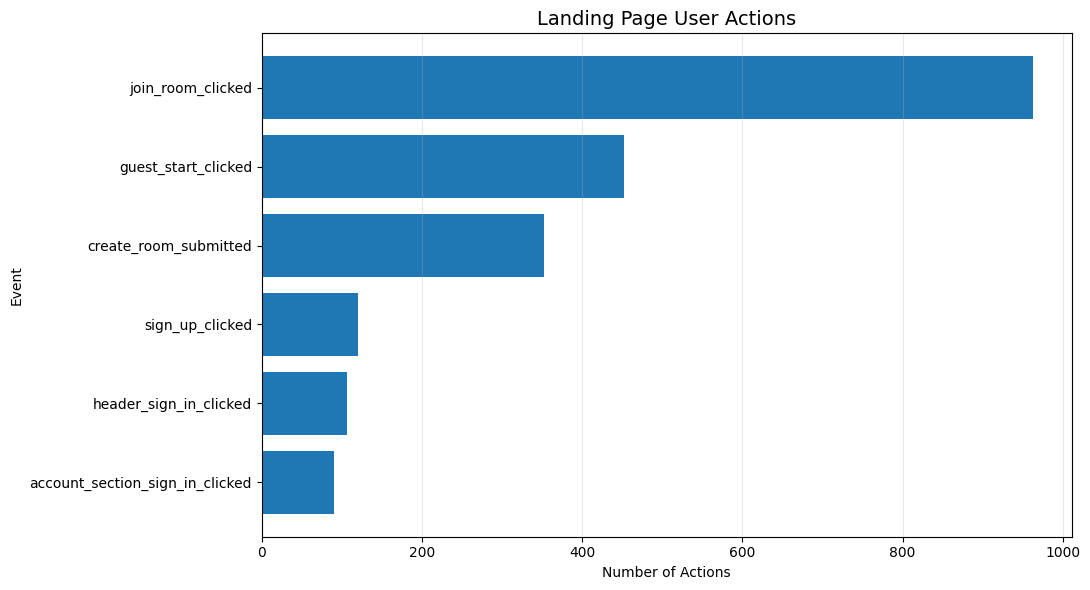

In [11]:
# Візуалізуємо найпопулярніші дії на Landing Page

landing_plot = landing_action_summary.sort_values(
    "total_events",
    ascending=True
)

fig, ax = plt.subplots(figsize=(11, 6))

ax.barh(
    landing_plot["event_name"],
    landing_plot["total_events"]
)

ax.set_title("Landing Page User Actions", fontsize=14)
ax.set_xlabel("Number of Actions")
ax.set_ylabel("Event")
ax.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

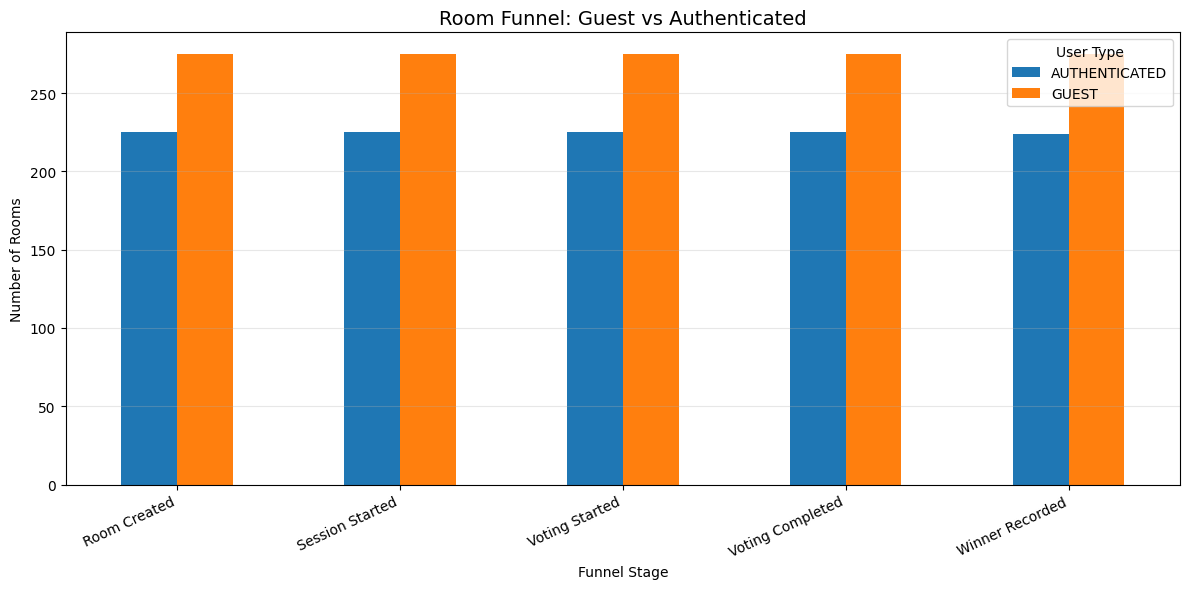

In [12]:
# Формуємо таблицю кількості кімнат за етапами

funnel_count_pivot = (
    room_funnel_summary
    .pivot(
        index="stage",
        columns="user_type",
        values="rooms_reached"
    )
    .reindex(funnel_order)
)

# Візуалізуємо проходження етапів воронки

fig, ax = plt.subplots(figsize=(12, 6))

funnel_count_pivot.plot(
    kind="bar",
    ax=ax
)

ax.set_title("Room Funnel: Guest vs Authenticated", fontsize=14)
ax.set_xlabel("Funnel Stage")
ax.set_ylabel("Number of Rooms")
ax.legend(title="User Type")
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

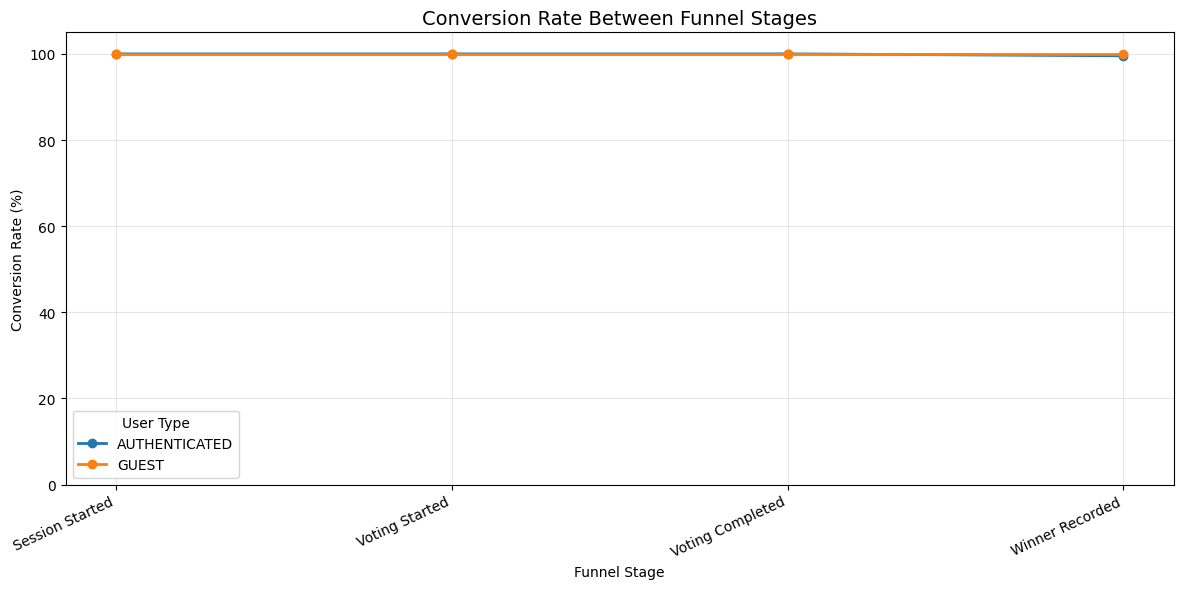

In [13]:
# Формуємо таблицю конверсії між етапами

conversion_pivot = (
    room_funnel_summary
    .pivot(
        index="stage",
        columns="user_type",
        values="conversion_from_previous_pct"
    )
    .reindex(funnel_order)
)

# Візуалізуємо конверсію між етапами

fig, ax = plt.subplots(figsize=(12, 6))

for user_type in conversion_pivot.columns:

    ax.plot(
        conversion_pivot.index,
        conversion_pivot[user_type],
        marker="o",
        linewidth=2,
        label=user_type
    )

ax.set_title("Conversion Rate Between Funnel Stages", fontsize=14)
ax.set_xlabel("Funnel Stage")
ax.set_ylabel("Conversion Rate (%)")
ax.set_ylim(0, 105)
ax.legend(title="User Type")
ax.grid(alpha=0.3)

plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

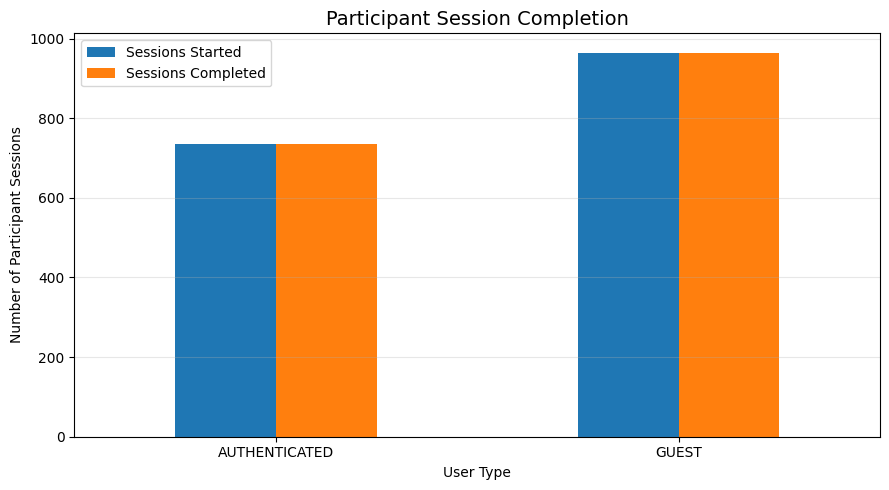

In [14]:
# Формуємо дані для порівняння сесій учасників

participant_plot = (
    participant_funnel_summary
    .set_index("user_type")[
        ["sessions_started", "sessions_completed"]
    ]
)

# Візуалізуємо кількість початих та завершених сесій

fig, ax = plt.subplots(figsize=(9, 5))

participant_plot.plot(
    kind="bar",
    ax=ax
)

ax.set_title("Participant Session Completion", fontsize=14)
ax.set_xlabel("User Type")
ax.set_ylabel("Number of Participant Sessions")
ax.legend([
    "Sessions Started",
    "Sessions Completed"
])
ax.grid(axis="y", alpha=0.3)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

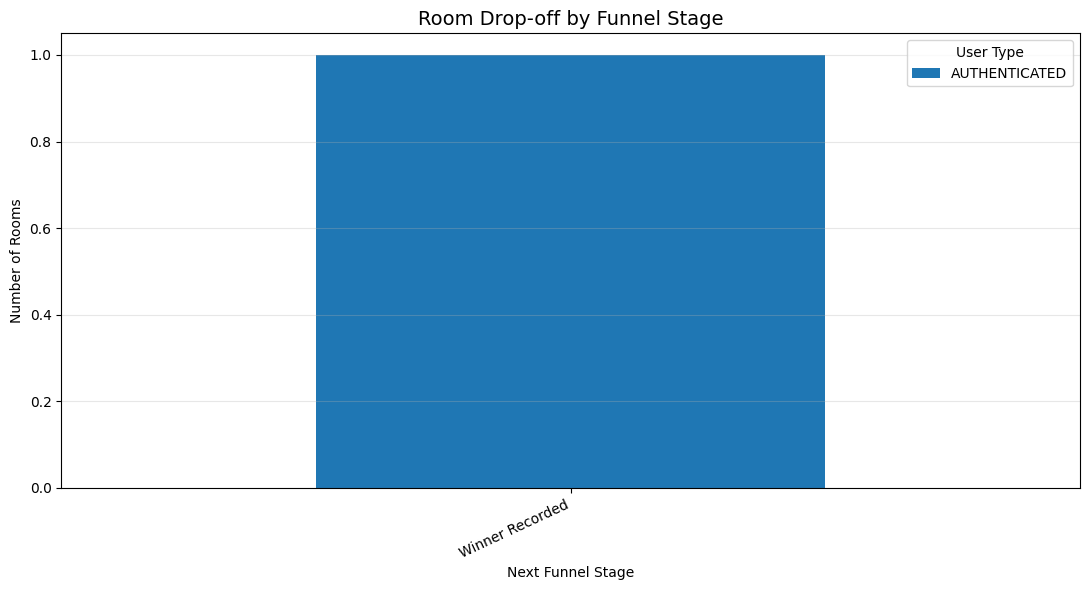

In [15]:
# Візуалізуємо кількість кімнат із точками відтоку

if not dropoff_summary.empty:

    dropoff_plot = (
        dropoff_summary
        .pivot(
            index="next_stage",
            columns="user_type",
            values="rooms"
        )
        .fillna(0)
    )

    fig, ax = plt.subplots(figsize=(11, 6))

    dropoff_plot.plot(
        kind="bar",
        ax=ax
    )

    ax.set_title("Room Drop-off by Funnel Stage", fontsize=14)
    ax.set_xlabel("Next Funnel Stage")
    ax.set_ylabel("Number of Rooms")
    ax.legend(title="User Type")
    ax.grid(axis="y", alpha=0.3)

    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

else:

    print("Точок відтоку не виявлено.")

In [16]:
# Формуємо зведену таблицю результатів воронки

funnel_final_summary = (
    room_funnel_summary[
        [
            "user_type",
            "stage",
            "rooms_with_event",
            "rooms_reached",
            "conversion_from_previous_pct",
            "cumulative_conversion_pct",
            "dropoff_rooms"
        ]
    ]
    .copy()
)

# Формуємо загальну статистику кімнат

room_totals = (
    room_journey
    .groupby("user_type")
    .agg(
        total_rooms=("room_id", "nunique"),
        rooms_with_winner=(
            "winner_record_valid",
            "sum"
        )
    )
    .reset_index()
)

# Додаємо інформацію про результат проходження

funnel_final_summary = funnel_final_summary.merge(
    room_totals,
    on="user_type",
    how="left"
)

print("Підсумкова таблиця воронок:")

display(
    funnel_final_summary.round(2)
)

print("Підсумкова статистика учасників:")

display(
    participant_funnel_summary.round(2)
)

print("Підсумкова статистика точок відтоку:")

display(
    dropoff_summary
)

Підсумкова таблиця воронок:


,user_type,stage,rooms_with_event,rooms_reached,conversion_from_previous_pct,cumulative_conversion_pct,dropoff_rooms,total_rooms,rooms_with_winner
0,GUEST,Room Created,275,275,NaN,100.00,0,275,275
1,GUEST,Session Started,275,275,100.00,100.00,0,275,275
2,GUEST,Voting Started,275,275,100.00,100.00,0,275,275
3,GUEST,Voting Completed,275,275,100.00,100.00,0,275,275
4,GUEST,Winner Recorded,275,275,100.00,100.00,0,275,275
5,AUTHENTICATED,Room Created,225,225,NaN,100.00,0,225,224
6,AUTHENTICATED,Session Started,225,225,100.00,100.00,0,225,224
7,AUTHENTICATED,Voting Started,225,225,100.00,100.00,0,225,224
8,AUTHENTICATED,Voting Completed,225,225,100.00,100.00,0,225,224
9,AUTHENTICATED,Winner Recorded,224,224,99.56,99.56,1,225,224


Підсумкова статистика учасників:


,user_type,sessions_started,sessions_completed,sessions_without_completion,completion_rate_pct,avg_session_duration_min,median_session_duration_min
0,AUTHENTICATED,735,735,0,100.0,25.69,25.63
1,GUEST,965,965,0,100.0,25.58,25.70


Підсумкова статистика точок відтоку:


,user_type,last_successful_stage,next_stage,dropoff_reason,rooms
0,AUTHENTICATED,Voting Completed,Winner Recorded,Подію визначення переможця не знайдено,1



**1. Аналіз дій користувачів на Landing Page**

На початковій сторінці продукту було зафіксовано **2 008 унікальних відвідувачів**.

Найпопулярнішою дією стало приєднання до вже створеної кімнати (`join_room_clicked`), яке виконали 780 унікальних відвідувачів. Це становить **38,84%** відвідувачів сторінки.

Інші популярні дії:

- `guest_start_clicked` — 452 унікальні відвідувачі (22,51%);
- `create_room_submitted` — 315 унікальних відвідувачів (15,69%);
- `sign_up_clicked` — 120 унікальних відвідувачів (5,98%);
- `header_sign_in_clicked` — 106 унікальних відвідувачів (5,28%);
- `account_section_sign_in_clicked` — 90 унікальних відвідувачів (4,48%).

Отримані результати показують, що найпоширенішими варіантами взаємодії з Landing Page є приєднання до вже створеної кімнати та початок гостьового сценарію. Дії, пов'язані з реєстрацією та авторизацією, мають меншу частку охоплення.

Водночас варто враховувати, що один відвідувач міг виконувати декілька різних дій. Тому наведені частки характеризують охоплення окремих подій, а не послідовну конверсію між етапами користувацького сценарію.

---

**2. Аналіз воронки Guest**

Для сегмента **Guest** було проаналізовано 275 унікальних ігрових кімнат.

За результатами дослідження всі 275 кімнат успішно пройшли основні етапи продуктового сценарію:

- Створення кімнати (`Room Created`) — 275 кімнат.
- Запуск сесії (`Session Started`) — 275 кімнат.
- Початок голосування (`Voting Started`) — 275 кімнат.
- Завершення голосування (`Voting Completed`) — 275 кімнат.
- Фіксація переможця (`Winner Recorded`) — 275 кімнат.

Конверсія між усіма послідовними етапами становить **100%**. Втрат між етапами не виявлено.

Таким чином, усі створені гостьовими користувачами кімнати пройшли повний досліджуваний сценарій — від створення до фіксації переможця.

---

**3. Аналіз воронки Authenticated**

Для сегмента **Authenticated** було проаналізовано 225 унікальних ігрових кімнат.

Результати проходження основних етапів:

- Створення кімнати (`Room Created`) — 225 кімнат.
- Запуск сесії (`Session Started`) — 225 кімнат.
- Початок голосування (`Voting Started`) — 225 кімнат.
- Завершення голосування (`Voting Completed`) — 225 кімнат.
- Фіксація переможця (`Winner Recorded`) — 224 кімнати.

Конверсія між першими чотирма етапами становить **100%**. На останньому етапі показник знижується до **99,56%**.

Було виявлено одну кімнату (`room_id = 500004`), для якої зафіксовано завершення голосування, але відсутня подія визначення переможця `movie_won`.

Отже, 224 із 225 кімнат (99,56%) досягли фінального етапу. Основні етапи сценарію Authenticated проходять без втрат до завершення голосування, а єдина виявлена проблема пов'язана з відсутністю фінального запису про переможця.

---

**4. Аналіз завершеності голосування на рівні учасників (Participant Session Analysis)**

Окремо було досліджено проходження голосування на рівні унікальних пар `room_id + participant_id`, оскільки одна кімната може містити декількох учасників.

Загалом було зафіксовано **1 700 унікальних сесій учасників**:

- Authenticated — 735 сесій;
- Guest — 965 сесій.

У всіх 1 700 випадках було зафіксовано як початок, так і коректне завершення голосування. Відповідно, показник завершення сесій становить **100% для обох сегментів**.

Середня та медіанна тривалість голосування:

- Authenticated — середня тривалість 25,69 хвилини, медіанна — 25,63 хвилини.
- Guest — середня тривалість 25,58 хвилини, медіанна — 25,70 хвилини.

Різниця між тривалістю голосування в обох сегментах є незначною.

Додаткова перевірка не виявила завершених сесій без відповідної події початку або випадків, коли завершення було зафіксовано раніше початку.

Таким чином, у досліджуваних даних голосування учасників характеризується повною реєстрацією подій початку та завершення в обох сегментах.

---

**5. Аналіз точок відтоку (Drop-off Analysis)**

Перевірка всіх 500 кімнат дозволила виявити лише одну точку відтоку.

Вона стосується кімнати `500004` із сегмента Authenticated, для якої останнім успішно пройденим етапом стало завершення голосування (`Voting Completed`), після чого не було зафіксовано подію `Winner Recorded`.

Основні результати:

- Загальна кількість створених кімнат — 500.
- Кількість кімнат, які пройшли всі етапи, — 499.
- Кількість кімнат без фінального результату — 1.
- Загальна частка завершення сценарію — **99,8%**.

Отже, єдина виявлена точка відтоку знаходиться між завершенням голосування та реєстрацією переможця.

Цей випадок доцільно додатково перевірити на рівні логіки обробки результатів, щоб з'ясувати причину відсутності події `movie_won`.

---

**6. Перевірка часової послідовності подій**

Додатково було перевірено правильність часової послідовності ключових етапів користувацького сценарію.

Результати перевірки:

- Не виявлено запусків сесій раніше створення кімнати.
- Не виявлено початку голосування раніше запуску сесії.
- Не виявлено фіксації переможця раніше завершення голосування.
- Не виявлено завершень сесій учасників раніше початку голосування.
- Не виявлено завершених сесій без відповідної події початку.

Таким чином, усі перевірені часові послідовності відповідають очікуваній логіці продуктового сценарію.

Водночас відсутність події `movie_won` для однієї кімнати не є порушенням часової послідовності, але свідчить про відсутність очікуваного фінального запису в аналітичних даних.

---

**Загальний підсумок**

Проведений аналіз користувацького шляху та воронок конверсії дозволив визначити основні особливості взаємодії з продуктом **Movie Match**:

- Найпопулярнішою дією на Landing Page є приєднання до існуючої кімнати, яке охоплює 38,84% унікальних відвідувачів сторінки.
- У сегменті Guest усі 275 кімнат пройшли повний досліджуваний сценарій із конверсією 100% між кожним етапом.
- У сегменті Authenticated 224 із 225 кімнат досягли етапу фіксації переможця, що відповідає конверсії 99,56%.
- Усі 1 700 сесій учасників мають зафіксовані події початку та завершення голосування.
- Середня тривалість голосування для Guest та Authenticated майже однакова і становить приблизно 25,6 хвилини.
- Єдина виявлена точка відтоку пов'язана з відсутністю події визначення переможця в одній Authenticated-кімнаті.
- Перевірка часових міток не виявила порушень послідовності основних подій.

Результати дослідження демонструють високий рівень завершеності основного продуктового сценарію в межах досліджуваного набору даних. Окрему увагу надалі доцільно приділити перевірці механізму фіксації результатів голосування та причин відсутності події `movie_won` для кімнати `500004`.